# Rediscovering a Band Structure with Symbolic Regression

**Goal:** Recover the dispersion $E(k)$ of a two-site 1D tight-binding chain (SSH-type) from numerical data alone, using PySR.

**Conventions:** $\hbar = a = 1$. Hoppings: $t_1$ within a cell, $t_2$ between cells.

**Physics**
$$h(k) = t_1 + t_2 e^{ik}, \qquad H(k) = \begin{pmatrix} 0 & h \\ h^* & 0 \end{pmatrix}, \qquad E_\pm(k) = \pm\sqrt{t_1^2 + t_2^2 + 2t_1t_2\cos k}$$
- Gap $= 2|t_1 - t_2|$ at $k = \pi$; band top $= t_1 + t_2$ at $k = 0$.

**Simple case:** $t_1 = 1.0,\ t_2 = 0.5 \Rightarrow E_+ = \sqrt{1.25 + 1.0\cos k}$ (gap $= 1.0$, top $= 1.5$).

**Plan**
1. Generate the data: diagonalize $H(k)$ with `eigvalsh` on about 200 $k$-points in $[-\pi, \pi]$ and keep the upper band. *No closed form is used for the data.*
2. Run PySR on $(k, E)$ only, with deterministic and serial settings as in notebook 11 (`random_state=0`). Operators are $+, \times, \cos, \sqrt{}$, with decoys $\sin, \exp$.
   - Target: $\sqrt{a + b\cos k}$ (complexity ≈ 7). Decoy: $a + b\cos k$ (complexity ≈ 5, ~10% off at $k=\pi/2$).
3. Test robustness: clean data, then 1% noise, then 20% noise. Pick the knee of the hall of fame by hand.
4. Extrapolate: train on part of the $k$-range and test on the held-out part.
5. Invert for the hoppings: $(t_1+t_2)^2 = a+b$ and $(t_1-t_2)^2 = a-b$. Which value is $t_1$ and which is $t_2$ can't be determined, because the spectrum is symmetric under $t_1 \leftrightarrow t_2$.

**Checks**
- Numerical $E$ matches the closed form to about $10^{-12}$.
- $E(k) = E(-k)$.
- Gap $= 2|t_1 - t_2|$.
- The recovered formula gives the correct $E(0)$ and $E(\pi)$.
- The held-out error is small.

**Later:** extend to a more complex case.


In [1]:
# Install PySR into this kernel's environment (run once; then restart the kernel)
%pip install pysr


Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import relevant libraries
# Conventions: hbar = a = 1 (lattice constant), so k is dimensionless in [-pi, pi]
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

os.environ["PYTHON_JULIACALL_HANDLE_SIGNALS"] = "yes"   # PySR's docs ask for this in Jupyter (as in notebook 11)
from pysr import PySRRegressor                          # first import downloads Julia; takes a few minutes


In [3]:
# Two-site (SSH-type) chain. Conventions: hbar = a = 1, so k is in [-pi, pi]; energies in the same units as t.
# t1 = hopping within a cell, t2 = hopping between cells.
T1, T2 = 1.0, 0.5        # simple case: a = t1^2 + t2^2 = 1.25, b = 2 t1 t2 = 1.0, gap = 1.0, band top = 1.5
K_MAX = 2 * np.pi / 3    # train on |k| <= K_MAX; hold out |k| > K_MAX (contains the gap at k = pi)
LEVELS = [0.01, 0.2, 0.5, 0.75]             # relative noise standard deviations
NOISE = {                                   # unit-variance samplers, so every distribution has std = level * E
    "gaussian": lambda rng, n: rng.normal(0, 1, n),
    "uniform":  lambda rng, n: rng.uniform(-np.sqrt(3), np.sqrt(3), n),
    "laplace":  lambda rng, n: rng.laplace(0, 1 / np.sqrt(2), n),     # heavy tails: occasional large outliers
}

def bloch_bands(k, t1, t2):
    """Both bands at each k from diagonalizing H(k) = [[0, h], [h*, 0]], h = t1 + t2 e^{ik}. Shape (len(k), 2), low to high."""
    h = t1 + t2 * np.exp(1j * k)
    H = np.zeros((len(k), 2, 2), dtype=complex)
    H[:, 0, 1], H[:, 1, 0] = h, h.conj()
    return np.linalg.eigvalsh(H)

def add_noise(E, level, dist, seed=0):
    """Relative noise: E * (1 + level * x), x drawn from NOISE[dist] (zero mean, unit variance). Same seed at every level."""
    return E * (1 + level * NOISE[dist](np.random.default_rng(seed), len(E)))

def generate_data(t1, t2, level, dist, num_points=201):
    """Upper band on a symmetric k-grid (odd num_points, so k = 0 and +-pi are on it), with relative noise."""
    k = np.linspace(-np.pi, np.pi, num_points)
    return k, add_noise(bloch_bands(k, t1, t2)[:, 1], level, dist)

def check_data(k, t1, t2):
    """Clean numerical bands vs. the closed form (used only here, as a check), E(k) = E(-k), and the gap."""
    bands = bloch_bands(k, t1, t2)
    err = np.abs(bands[:, 1] - np.sqrt(t1**2 + t2**2 + 2 * t1 * t2 * np.cos(k))).max()
    gap = bands[:, 1].min() - bands[:, 0].max()
    print(f"max |E_num - E_closed| = {err:.1e}")
    print(f"gap = {gap:.12f}, expected 2|t1 - t2| = {2 * abs(t1 - t2)}")
    assert err < 1e-12
    assert np.allclose(bands[:, 1], bands[::-1, 1], rtol=0, atol=1e-12)   # E(k) = E(-k): the grid is symmetric
    assert np.isclose(gap, 2 * abs(t1 - t2), rtol=0, atol=1e-12)

def fit_model(k, E):
    """PySR on (k, E) only, with the deterministic settings from notebook 11. Prints the hall of fame."""
    model = PySRRegressor(
        niterations=40, verbosity=0, progress=False,
        random_state=0, deterministic=True, parallelism="serial",   # the same search on every run
        binary_operators=["+", "*"],
        unary_operators=["cos", "sqrt", "sin", "exp"],              # sin and exp are decoys
        maxsize=20,
    )
    model.fit(k.reshape(-1, 1), E)    # PySR wants X with shape (samples, features)
    print(model.equations_[["complexity", "loss", "equation"]].to_string())
    return model

def band_summary(f):
    """For an upper band f(k): E(0), E(pi), a = (E(0)^2 + E(pi)^2)/2, b = (E(0)^2 - E(pi)^2)/2, gap = 2 min_k f,
    and the SSH hoppings (E(0) +- E(pi))/2 (true t1, t2 only if Delta = 0; which is which is not recoverable)."""
    E0, Epi = f(np.array([0.0, np.pi]))
    return {"E(0)": E0, "E(pi)": Epi, "a": (E0**2 + Epi**2) / 2, "b": (E0**2 - Epi**2) / 2,
            "gap": 2 * f(np.linspace(-np.pi, np.pi, 401)).min(), "t (Delta=0)": (E0 + Epi) / 2, "t' (Delta=0)": (E0 - Epi) / 2}

def evaluate(model, index, upper_band):
    """Chosen hall-of-fame row vs. the clean upper band: band_summary of each, plus the held-out max relative error."""
    f = lambda k: model.predict(k.reshape(-1, 1), index=index)
    k_test = np.linspace(K_MAX, np.pi, 50)
    fit = band_summary(f) | {"held-out err": np.abs(f(k_test) / upper_band(k_test) - 1).max()}
    return pd.DataFrame({"truth": band_summary(upper_band), "PySR": fit}).T

def plot_results(ax, k, E, model, index, title):
    """On axis ax: data, hall-of-fame rows 0..index (simplest to chosen; chosen in red), held-out region shaded."""
    ax.scatter(k, E, s=8, color="black", alpha=0.4, label="data (numerical upper band)")
    for j in range(index + 1):
        row = model.equations_.iloc[j]
        style = dict(color="red", ls="--", lw=2) if j == index else dict(lw=1.5)
        label = f"row {j} (complexity {row.complexity}): {row.equation.replace('x0', 'k')}"
        ax.plot(k, model.predict(k.reshape(-1, 1), index=j), label=label, **style)
    for lo, hi in [(-np.pi, -K_MAX), (K_MAX, np.pi)]:
        ax.axvspan(lo, hi, color="gray", alpha=0.2)
    ax.set(xlabel="k", ylabel="E", title=f"{title} (gray: held out)")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))   # below the axes

def sweep(data_fn):
    """Fit every (distribution, level). data_fn(level, dist) -> (k, E). Returns {(dist, level): (k, E, model)}."""
    results = {}
    for dist in NOISE:
        for level in LEVELS:
            print(f"\n--- {dist}, {level:.0%} noise ---")
            k, E = data_fn(level, dist)
            train = np.abs(k) <= K_MAX
            results[dist, level] = (k, E, fit_model(k[train], E[train]))
    return results

def sweep_table(results, knees, upper_band):
    """One row per (dist, level): the hand-picked formula and its band_summary + held-out error."""
    rows = {key: {"row": knees[key], "equation": m.equations_.equation[knees[key]].replace("x0", "k")}
                 | evaluate(m, knees[key], upper_band).loc["PySR"].to_dict() for key, (k, E, m) in results.items()}
    return pd.DataFrame(rows).T.infer_objects().rename_axis(["noise", "level"])   # numeric columns, so .round works

def plot_sweep(results, knees, title):
    """One figure per noise distribution, one panel per level."""
    for dist in NOISE:
        fig, axes = plt.subplots(1, len(LEVELS), figsize=(6 * len(LEVELS), 4.5), sharey=True)
        for ax, level in zip(axes, LEVELS):
            k, E, m = results[dist, level]
            plot_results(ax, k, E, m, knees[dist, level], f"{title}, {dist} {level:.0%}")
        plt.show()

def plot_gaps(fits, bands_fn, true_gap):
    """One panel per (model, row, title): numerical bands (gray), PySR +-E_+ (red), forbidden energies shaded."""
    kk = np.linspace(-np.pi, np.pi, 401)
    bands = bands_fn(kk)
    fig, axes = plt.subplots(1, len(fits), figsize=(4.5 * len(fits), 4.5), sharey=True)
    for ax, (m, row, title) in zip(axes, fits):
        Ep = m.predict(kk.reshape(-1, 1), index=row)    # fitted upper band; lower band is -Ep (chiral symmetry)
        lo, hi = Ep.min(), Ep.max()
        ax.plot(kk, bands, color="black", lw=4, alpha=0.25)
        ax.plot(kk, Ep, "r--", kk, -Ep, "r--")
        for a, b in [(-lo, lo), (hi, 2.5), (-2.5, -hi)]:  # gap, and above/below the bands
            ax.axhspan(a, b, color="C0", alpha=0.15)
        ax.set(xlabel="k", ylim=(-2.5, 2.5), title=f"{title}: $E_g$ = {2 * lo:.3f} (true {true_gap:.3f})")
    axes[0].set_ylabel("E")
    fig.suptitle("Shaded: forbidden energies.  Gray: numerical bands.  Red dashed: PySR $\\pm E_+$.", y=1.02)
    plt.show()

def plot_gap_vs_noise(table, true_gap, title):
    """Recovered gap against noise level, one line per distribution."""
    for dist in NOISE:
        plt.plot([100 * l for l in LEVELS], table.loc[dist, "gap"].astype(float), "o-", label=dist)
    plt.axhline(true_gap, color="black", ls=":", label=f"true gap {true_gap:.3f}")
    plt.xlabel("noise level (% of E, std)"); plt.ylabel("$E_g$ from PySR"); plt.title(title); plt.legend(); plt.show()


In [4]:
# Simple case: generate the clean data, check it, and split off the held-out k range
k, E = generate_data(T1, T2, 0.0, "gaussian")   # level 0: no noise
check_data(k, T1, T2)
train = np.abs(k) <= K_MAX
k_train, E_train = k[train], E[train]


max |E_num - E_closed| = 4.4e-16
gap = 1.000000000000, expected 2|t1 - t2| = 1.0


   complexity          loss                                                                                     equation
0           1  3.722594e-02                                                                                    1.2761592
1           4  9.816873e-03                                                                           sqrt(exp(cos(x0)))
2           5  1.602728e-15                                                                         sqrt(cos(x0) + 1.25)
3          11  1.175334e-15                                    sqrt(sqrt((cos(x0) + 1.2499993) * (cos(x0) + 1.2500007)))
4          18  7.479397e-16  sqrt(sqrt((cos(x0) + 1.2500007) * (sqrt(cos(x0) + 1.2499993) * sqrt(cos(x0) + 1.2499993))))


,E(0),E(pi),a,b,gap,t (Delta=0),t' (Delta=0),held-out err
truth,1.5,0.5,1.25,1.0,1.0,1.0,0.5,NaN
PySR,1.5,0.5,1.25,1.0,1.0,1.0,0.5,0.0


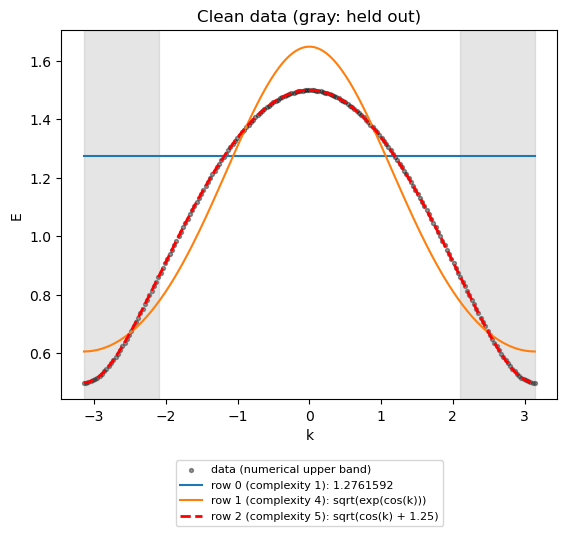

In [5]:
# Clean fit: PySR on the training k only, then the knee of the hall of fame, picked by hand
model = fit_model(k_train, E_train)

i = 2   # knee: sqrt(cos(k) + 1.25); the loss drops to ~0 here and longer rows only add redundant terms
ssh_band = lambda k: bloch_bands(k, T1, T2)[:, 1]
display(evaluate(model, i, ssh_band).round(4))
fig, ax = plt.subplots()
plot_results(ax, k, E, model, i, "Clean data")
plt.show()


**Clean-fit result** ($t_1 = 1.0,\ t_2 = 0.5$)

| | $E_+(k)$ |
|---|---|
| Analytic | $\sqrt{t_1^2 + t_2^2 + 2t_1t_2\cos k} = \sqrt{1.25 + \cos k}$ |
| PySR (row 2, complexity 5) | $\sqrt{\cos k + 1.25}$ |

The two are identical. The held-out error is 0.00%, and the recovered hoppings are $1.0$ and $0.5$.


In [6]:
# Noise sweep: 3 distributions x 4 levels, each with std = level * E (same seed, so each level rescales the same draw)
results = sweep(lambda level, dist: generate_data(T1, T2, level, dist))



--- gaussian, 1% noise ---


    complexity      loss                                                                                              equation
0            1  0.037249                                                                                              1.276919
1            4  0.010101                                                                                    sqrt(exp(cos(x0)))
2            5  0.000163                                                                             sqrt(cos(x0) + 1.2519934)
3            7  0.000160                                                               sqrt(cos(x0 + 0.005271552) + 1.2520034)
4            9  0.000160                                                    sqrt((x0 * -0.0032620889) + (cos(x0) + 1.2519996))
5           11  0.000160                                     sqrt((x0 * -0.003263363) + (cos(x0) + 1.2549671)) + -0.0012287389
6           12  0.000159                                        sqrt(cos(x0 + (exp(cos(exp(x0))) * 0.0033163887

    complexity      loss                                                                   equation
0            1  0.099719                                                                   1.291471
1            4  0.077755                                                         sqrt(exp(cos(x0)))
2            5  0.065279                                                  sqrt(cos(x0) + 1.2899888)
3            6  0.065230                                              cos(x0 * 0.44973) * 1.5030687
4            7  0.064003                                     sqrt(cos(x0 + 0.10753326) + 1.2928756)
5            8  0.063961                            sin((x0 * 0.56134456) + 1.6315715) + 0.50689256
6            9  0.063933                          sqrt(((x0 * -0.066084325) + cos(x0)) + 1.2920285)
7           10  0.063728                    sqrt(sin(cos(x0 + 0.108393885) * 1.125066) + 1.3089176)
8           13  0.063359            sqrt(cos(x0) + sqrt(sqrt(cos(exp(x0) * 6.6302156) + 2.768135)))


    complexity      loss                                                                                      equation
0            1  0.438359                                                                                     1.3144774
1            4  0.425444                                                                            sqrt(exp(cos(x0)))
2            5  0.407998                                                                     sqrt(cos(x0) + 1.3509386)
3            6  0.407370                                                                sqrt(sin(cos(x0)) + 1.3862962)
4            7  0.400019                                                         sqrt(cos(x0 + 0.2779484) + 1.3695881)
5            8  0.399489                                                    sqrt(sin(cos(x0 + 0.2918071)) + 1.4021802)
6           10  0.387100                                                   sqrt(exp(cos(x0 + sin(exp(exp(cos(x0)))))))
7           11  0.384331                        

   complexity      loss                                                                equation
0           1  0.945050                                                               1.3336548
1           4  0.940483                                                      sqrt(exp(cos(x0)))
2           5  0.918001                                                sqrt(cos(x0) + 1.402409)
3           7  0.900106                                  sqrt(cos(x0 + 0.43038836) + 1.4452232)
4           9  0.884011                                  sqrt(exp(cos(x0 + sin(exp(exp(x0))))))
5          10  0.850560                             sqrt(exp(cos(x0 + sin(exp(exp(cos(x0)))))))
6          12  0.832936               sqrt(exp(cos((x0 + 0.2771464) + sin(exp(exp(cos(x0)))))))
7          13  0.832024          sqrt(exp(cos((x0 + 0.2771464) + sin(sin(exp(exp(cos(x0))))))))
8          14  0.817571  sqrt(exp(cos(x0 + (sin(exp(exp(cos(x0)))) + 0.29818383)))) * 1.0990155

--- uniform, 1% noise ---


   complexity      loss                                                                                          equation
0           1  0.038153                                                                                         1.2777002
1           4  0.009529                                                                                sqrt(exp(cos(x0)))
2           5  0.000186                                                                         sqrt(cos(x0) + 1.2530608)
3           7  0.000181                                                             sqrt(cos(x0 * 1.0089763) + 1.2631177)
4           8  0.000178                                                   (cos(x0 * 0.69798505) + 1.1010935) * 0.71678376
5          14  0.000178                      sqrt(exp(cos(cos(x0 + 0.12978365)) * -0.049642332) + (cos(x0) + 0.29439598))
6          15  0.000176                   sqrt(exp((cos(cos(cos(x0 + 1.8570106))) * -0.06224636) + 0.27296713) + cos(x0))
7          16  0.000174 

... (3 outputs left out)

    complexity      loss                                                                                  equation
0            1  0.038028                                                                                 1.2776715
1            4  0.009603                                                                        sqrt(exp(cos(x0)))
2            5  0.000182                                                                 sqrt(cos(x0) + 1.2531123)
3            7  0.000178                                                     sqrt(cos(x0 * 1.0077491) + 1.2617874)
4            9  0.000176                                     sqrt((cos(x0) * 1.1689005) + 1.7128645) + -0.19237395
5           12  0.000174                            sqrt(cos((sin(x0 + 0.525363) * 0.021396054) + x0) + 1.2659581)
6           13  0.000171                             sqrt(cos(x0 + (sin(cos(x0) + x0) * 0.021374585)) + 1.2668701)
7           14  0.000171                        sqrt(cos(x0 + (sin(sin(cos(x0) +

    complexity      loss                                                                            equation
0            1  0.122240                                                                           1.3064675
1            4  0.075395                                                                  sqrt(exp(cos(x0)))
2            5  0.072873                                                           sqrt(cos(x0) + 1.3134694)
3            6  0.070762                                                  (cos(x0) * 0.47928956) + 1.1071972
4            7  0.070438                                              exp(cos(x0) * 0.41428804) + 0.09609027
5            8  0.070416                                        exp(sin(cos(x0) * 0.42448828)) + 0.095605105
6            9  0.069992                                exp(cos(x0 + 0.059291657) * 0.41587436) + 0.09534369
7           10  0.069939                            sqrt(exp(cos(x0 + 0.0680505) + -0.17973235) + 0.3554517)
8           12  0.0

    complexity      loss                                                                                 equation
0            1  0.522023                                                                                1.3519938
1            4  0.449474                                                                       sqrt(exp(cos(x0)))
2            5  0.445648                                                                exp(cos(x0) * 0.56355065)
3            6  0.441877                                                          sqrt(exp(cos(x0))) + 0.08716065
4            7  0.439356                                                      cos(cos(x0 + 4.889654)) * 1.8698035
5            8  0.438831                                             sqrt(exp(cos(x0 + 0.12365778))) + 0.08839955
6            9  0.434347                                       cos(cos((x0 * 0.8564227) + 1.7213957)) * 1.8251808
7           10  0.431300                                            exp(exp(cos(x0 + 2.0

    complexity      loss                                                                                 equation
0            1  1.104748                                                                                1.3899196
1            4  1.013941                                                                       sqrt(exp(cos(x0)))
2            5  0.998628                                                                exp(cos(x0) * 0.62407094)
3            6  0.996534                                                           sqrt(exp(cos(x0))) * 1.1017992
4            7  0.979114                                                     cos(cos(x0 + 1.7783881)) * 1.9379284
5            8  0.970050                                                         cos(sin(exp(x0))) * exp(cos(x0))
6            9  0.962677                                                         exp(cos(cos(x0) + x0) * cos(x0))
7           10  0.956280                                                    exp(cos(x0) 

row                  equation   E(0)  E(pi)      a      b  \
noise    level                                                              
gaussian 0.01     2  sqrt(cos(k) + 1.2519934)  1.501  0.502  1.252  1.000   
         0.20     2  sqrt(cos(k) + 1.2899888)  1.513  0.539  1.290  1.000   
         0.50     2  sqrt(cos(k) + 1.3509386)  1.533  0.592  1.351  1.000   
         0.75     2   sqrt(cos(k) + 1.402409)  1.550  0.634  1.402  1.000   
uniform  0.01     2  sqrt(cos(k) + 1.2530608)  1.501  0.503  1.253  1.000   
         0.20     1         sqrt(exp(cos(k)))  1.649  0.607  1.543  1.175   
         0.50     1         sqrt(exp(cos(k)))  1.649  0.607  1.543  1.175   
         0.75     1         sqrt(exp(cos(k)))  1.649  0.607  1.543  1.175   
laplace  0.01     2  sqrt(cos(k) + 1.2531123)  1.501  0.503  1.253  1.000   
         0.20     1         sqrt(exp(cos(k)))  1.649  0.607  1.543  1.175   
         0.50     1         sqrt(exp(cos(k)))  1.649  0.607  1.543  1.175   
         0.75     1         sqrt(exp(cos(k)))  1.649  0.607  1.543  1.175   

                  gap  t (Delta=0)  t' (Delta=0)  held-out err  
noise    level                                                  
gaussian 0.01   1.004        1.001         0.499         0.004  
         0.20   1.077        1.026         0.487         0.077  
         0.50   1.185        1.063         0.470         0.185  
         0.75   1.269        1.092         0.458         0.269  
uniform  0.01   1.006        1.002         0.499         0.006  
         0.20   1.213        1.128         0.521         0.213  
         0.50   1.213        1.128         0.521         0.213  
         0.75   1.213        1.128         0.521         0.213  
laplace  0.01   1.006        1.002         0.499         0.006  
         0.20   1.213        1.128         0.521         0.213  
         0.50   1.213        1.128         0.521         0.213  
         0.75   1.213        1.128         0.521         0.213

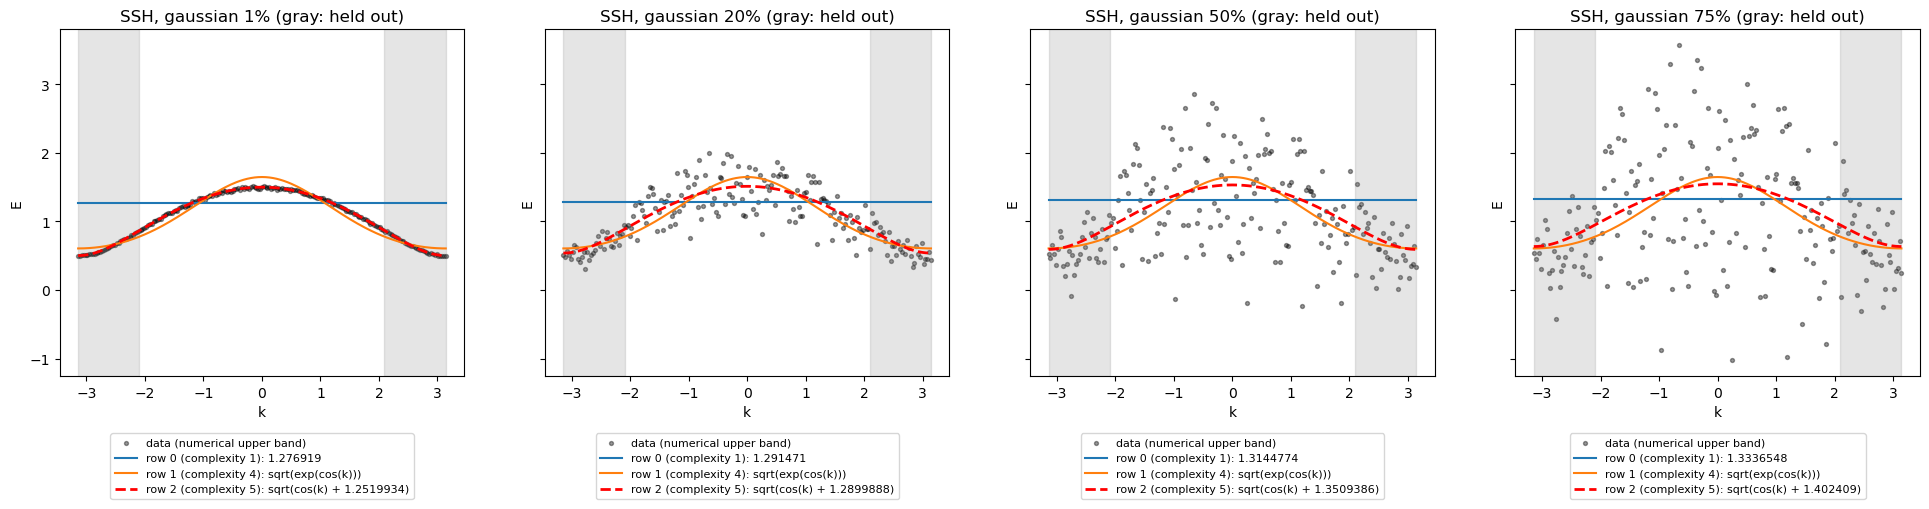

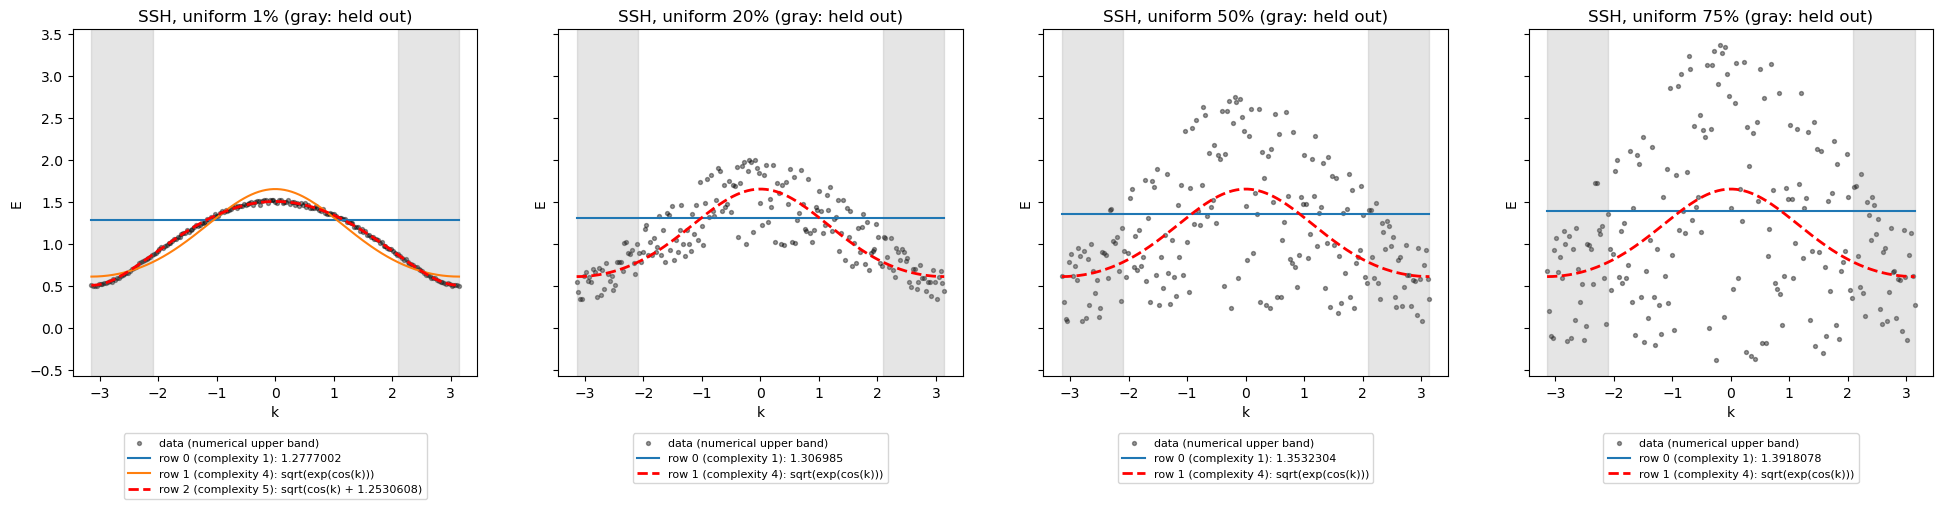

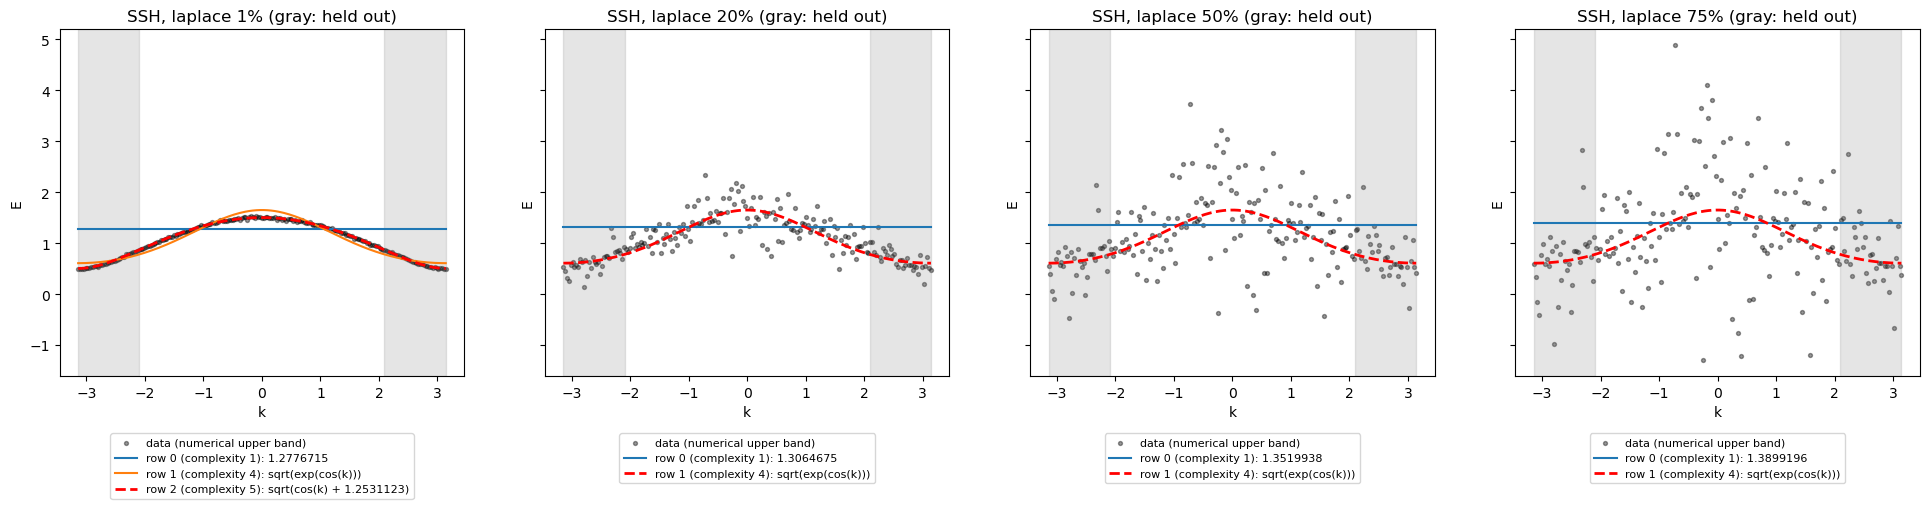

In [7]:
# Knees, picked by hand from the hall of fames above (the row after which the loss stops falling fast).
# Picked from training loss only; the held-out error was not used to choose.
KNEES = {("gaussian", 0.01): 2, ("gaussian", 0.2): 2, ("gaussian", 0.5): 2, ("gaussian", 0.75): 2,   # 75%: no clear knee
         ("uniform",  0.01): 2, ("uniform",  0.2): 1, ("uniform",  0.5): 1, ("uniform",  0.75): 1,
         ("laplace",  0.01): 2, ("laplace",  0.2): 1, ("laplace",  0.5): 1, ("laplace",  0.75): 1}
table = sweep_table(results, KNEES, ssh_band)
display(table.round(3))
plot_sweep(results, KNEES, "SSH")


**Noise-sweep results, SSH** (truth $\sqrt{1.25 + \cos k}$, $E_g = 1$). Each entry is the hand-picked knee, its gap, and its held-out error.

| Level | Gaussian | Uniform | Laplace |
|---|---|---|---|
| 1% | $\sqrt{\cos k + 1.252}$: 1.004, 0.4% | $\sqrt{\cos k + 1.253}$: 1.006, 0.6% | $\sqrt{\cos k + 1.253}$: 1.006, 0.6% |
| 20% | $\sqrt{\cos k + 1.290}$: 1.077, 7.7% | $\sqrt{e^{\cos k}}$: 1.213, 21% | $\sqrt{e^{\cos k}}$: 1.213, 21% |
| 50% | $\sqrt{\cos k + 1.351}$: 1.185, 19% | $\sqrt{e^{\cos k}}$: 1.213, 21% | $\sqrt{e^{\cos k}}$: 1.213, 21% |
| 75% | $\sqrt{\cos k + 1.402}$: 1.269, 27% (no clear knee) | $\sqrt{e^{\cos k}}$: 1.213, 21% | $\sqrt{e^{\cos k}}$: 1.213, 21% |

- At 1% noise, every distribution gives the exact form.
- From 20% noise on, uniform and Laplace noise lose the knee to $\sqrt{e^{\cos k}}$. That's a constant-free near-miss at complexity 4: the true form, one row later, lowers the loss by only about 1%. Gaussian noise keeps the true form, but its constant drifts.
- The drift grows linearly with the level, $a \approx 1.25 + 0.2 \times$ level. Every level rescales the same random draw, so this drift is a property of that one draw, not a systematic bias. One seed per case also can't rank the distributions.


**From the fitted band to the band gap.** Chiral (sublattice) symmetry, $\sigma_z H \sigma_z = -H$, forces $E_-(k) = -E_+(k)$. This symmetry is physics input; PySR doesn't learn it. So the fitted $E_+$ fixes the whole spectrum, and its extremes give the forbidden energies:
- Gap: $|E| < \min_k E_+ = E_+(\pi)$, so $E_g = 2E_+(\pi)$, which should equal $2|t_1 - t_2| = 1$.
- Above and below the bands: $|E| > \max_k E_+ = E_+(0) = t_1 + t_2$.


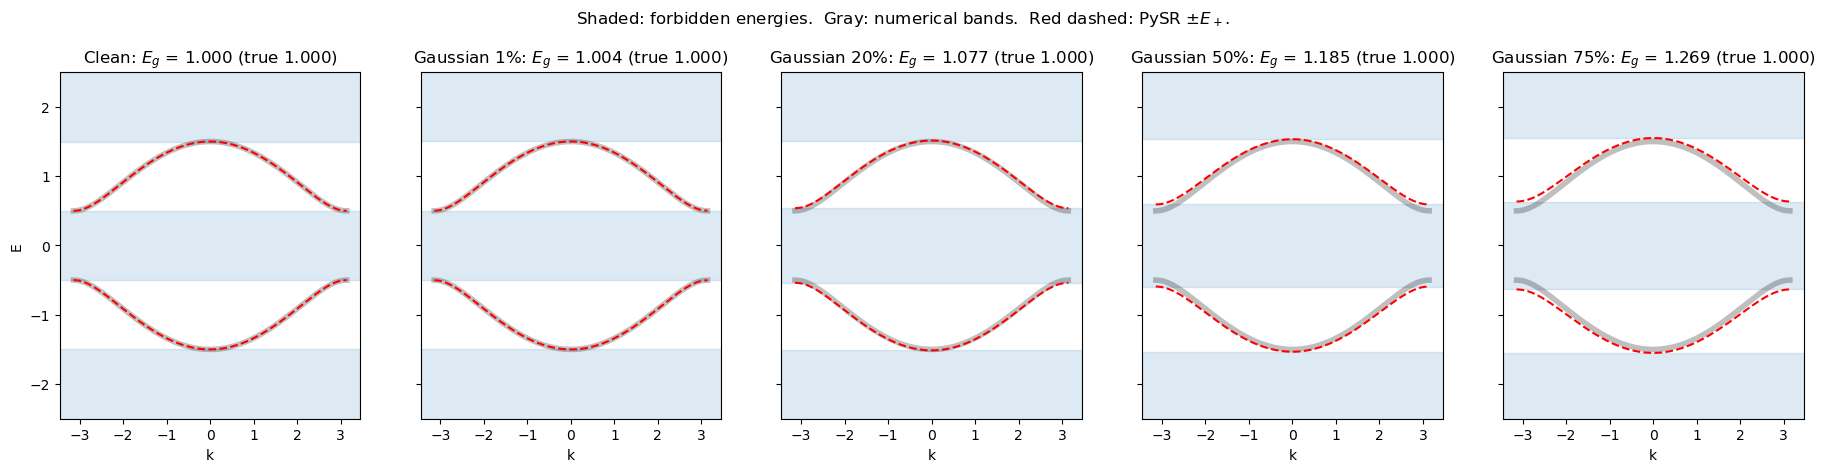

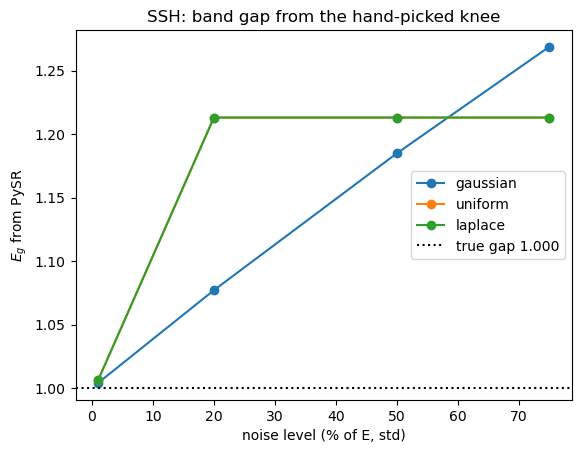

In [8]:
# Band gap from each PySR fit (E_- = -E_+): clean and the four Gaussian levels, then the gap vs. noise for every distribution
plot_gaps([(model, i, "Clean")] + [(results["gaussian", l][2], KNEES["gaussian", l], f"Gaussian {l:.0%}") for l in LEVELS],
          lambda k: bloch_bands(k, T1, T2), 2 * abs(T1 - T2))
plot_gap_vs_noise(table, 2 * abs(T1 - T2), "SSH: band gap from the hand-picked knee")


## Complex case: Rice–Mele chain

The Rice–Mele chain is the same chain with an added staggered on-site energy: $+\Delta$ on A sites and $-\Delta$ on B sites. Same conventions as before: $\hbar = a = 1$.
$$H(k) = \begin{pmatrix} \Delta & h \\ h^* & -\Delta \end{pmatrix}, \quad h = t_1 + t_2 e^{ik}, \qquad E_\pm(k) = \pm\sqrt{\Delta^2 + t_1^2 + t_2^2 + 2t_1t_2\cos k}$$
- $\Delta = 0$ gives back the SSH chain.
- Gap $= 2\sqrt{\Delta^2 + (t_1 - t_2)^2}$ at $k = \pi$, so it stays open even when $t_1 = t_2$. Band top $= \sqrt{\Delta^2 + (t_1 + t_2)^2}$ at $k = 0$.
- **Target formula:** still $\sqrt{a + b\cos k}$, now with $a = \Delta^2 + t_1^2 + t_2^2$ and $b = 2t_1t_2$.
- **New point, a degeneracy:** two fitted constants cannot fix three parameters. Only the combinations $t_1 t_2 = b/2$ and $\Delta^2 + t_1^2 + t_2^2 = a$ are recoverable, so this upper band alone cannot pin down $\Delta$.

**Checks:** same as the simple case, with the gap replaced by $2\sqrt{\Delta^2 + (t_1-t_2)^2}$ and the hopping recovery replaced by recovering $a$ and $b$.


In [9]:
# Define Rice-Mele model
def rice_mele_model(k, t1, t2, delta):
    """Both bands at each k from diagonalizing H(k) = [[delta, h], [h*, -delta]], h = t1 + t2 e^{ik}. Shape (len(k), 2), low to high."""
    h = t1 + t2 * np.exp(1j * k)
    H = np.zeros((len(k), 2, 2), dtype=complex)
    H[:, 0, 0], H[:, 1, 1] = delta, -delta
    H[:, 0, 1], H[:, 1, 0] = h, h.conj()
    return np.linalg.eigvalsh(H)

# Rice-Mele parameters: a = delta^2 + t1^2 + t2^2 = 1.5, b = 2 t1 t2 = 1.0, gap = 2 sqrt(delta^2 + (t1 - t2)^2) = 1.414, top = sqrt(2.5) = 1.581
T1_RM, T2_RM, DELTA = 1.0, 0.5, 0.5
A_RM, B_RM = DELTA**2 + T1_RM**2 + T2_RM**2, 2 * T1_RM * T2_RM
GAP_RM = 2 * np.sqrt(DELTA**2 + (T1_RM - T2_RM)**2)

def rm_upper_band(k):
    """Clean upper Rice-Mele band at the parameters above."""
    return rice_mele_model(k, T1_RM, T2_RM, DELTA)[:, 1]

def rm_data(level, dist, num_points=201):
    """Upper band on the same symmetric k-grid as the simple case, with relative noise."""
    k = np.linspace(-np.pi, np.pi, num_points)
    return k, add_noise(rm_upper_band(k), level, dist)

def check_rm_data(k):
    """Closed form (check only), Delta = 0 gives back SSH, E(k) = E(-k), E_- = -E_+, and the gap."""
    bands = rice_mele_model(k, T1_RM, T2_RM, DELTA)
    err = np.abs(bands[:, 1] - np.sqrt(A_RM + B_RM * np.cos(k))).max()
    gap = bands[:, 1].min() - bands[:, 0].max()
    print(f"max |E_num - E_closed| = {err:.1e}")
    print(f"gap = {gap:.12f}, expected 2 sqrt(delta^2 + (t1 - t2)^2) = {GAP_RM:.12f}")
    assert err < 1e-12
    assert np.allclose(rice_mele_model(k, T1_RM, T2_RM, 0.0), bloch_bands(k, T1_RM, T2_RM), rtol=0, atol=1e-12)
    assert np.allclose(bands[:, 1], bands[::-1, 1], rtol=0, atol=1e-12)
    assert np.allclose(bands[:, 0], -bands[:, 1], rtol=0, atol=1e-12)
    assert np.isclose(gap, GAP_RM, rtol=0, atol=1e-12)


max |E_num - E_closed| = 6.7e-16
gap = 1.414213562373, expected 2 sqrt(delta^2 + (t1 - t2)^2) = 1.414213562373


   complexity          loss             equation
0           1  3.172489e-02             1.372618
1           4  2.397588e-02   sqrt(exp(cos(x0)))
2           5  2.136971e-15  sqrt(cos(x0) + 1.5)


,E(0),E(pi),a,b,gap,t (Delta=0),t' (Delta=0),held-out err
truth,1.5811,0.7071,1.5,1.0,1.4142,1.1441,0.437,NaN
PySR,1.5811,0.7071,1.5,1.0,1.4142,1.1441,0.437,0.0


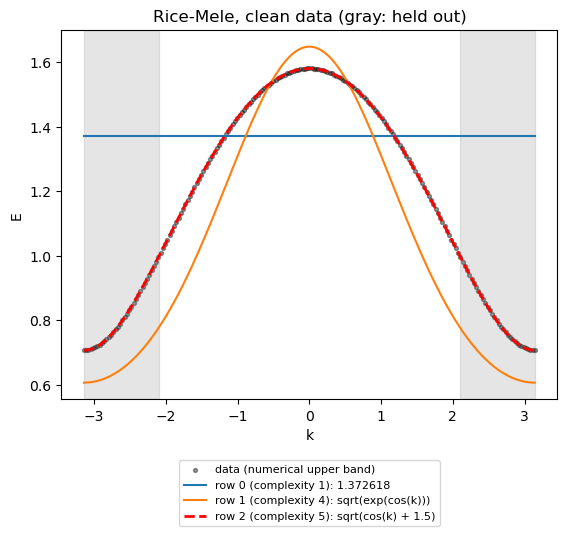

In [10]:
# Rice-Mele clean fit: check the data, fit on the training k, pick the knee by hand
k_rm, E_rm = rm_data(0.0, "gaussian")   # level 0: no noise
check_rm_data(k_rm)
train_rm = np.abs(k_rm) <= K_MAX
model_rm = fit_model(k_rm[train_rm], E_rm[train_rm])

i_rm = 2   # knee: sqrt(cos(k) + 1.5); loss drops to ~1e-15 here
display(evaluate(model_rm, i_rm, rm_upper_band).round(4))
fig, ax = plt.subplots()
plot_results(ax, k_rm, E_rm, model_rm, i_rm, "Rice-Mele, clean data")
plt.show()


**Rice–Mele clean-fit result** ($t_1 = 1.0,\ t_2 = 0.5,\ \Delta = 0.5$)

| | $E_+(k)$ |
|---|---|
| Analytic | $\sqrt{\Delta^2 + t_1^2 + t_2^2 + 2t_1t_2\cos k} = \sqrt{1.5 + \cos k}$ |
| PySR (row 2, complexity 5) | $\sqrt{\cos k + 1.5}$ |

The two are identical, the held-out error is 0.00%, and the fit recovers $a = 1.5$ and $b = 1.0$ exactly. Compared with SSH, the only change is $a$: 1.25 becomes 1.5. That is the degeneracy: an SSH chain with $t_1 \approx 1.144$, $t_2 \approx 0.437$ and $\Delta = 0$ has exactly the same band.


In [11]:
# Rice-Mele noise sweep: same distributions, levels, and seed as for SSH
results_rm = sweep(rm_data)



--- gaussian, 1% noise ---


    complexity      loss                                                                                         equation
0            1  0.031764                                                                                        1.3734467
1            4  0.024468                                                                               sqrt(exp(cos(x0)))
2            5  0.000188                                                                        sqrt(cos(x0) + 1.5023568)
3            7  0.000184                                                         sqrt(cos(x0 + 0.0063489242) + 1.5023708)
4            9  0.000184                                                sqrt(((x0 * -0.004019025) + 1.5023665) + cos(x0))
5           10  0.000184                                             sqrt((sin(x0 * -0.004019025) + 1.5023665) + cos(x0))
6           11  0.000183                                           sqrt(cos(((x0 * x0) * 0.0025811896) + x0) + 1.5023515)
7           12  0.000183

   complexity      loss                                                                  equation
0           1  0.103900                                                                 1.3893354
1           5  0.075120                                                  sqrt(cos(x0) + 1.547315)
2           6  0.075055                                           cos(x0 * -0.4173546) * 1.582334
3           7  0.073578                                     sqrt(cos(x0 + 0.12969983) + 1.551285)
4           8  0.073486                       cos((x0 * -0.53456396) + -0.069803394) + 0.58656764
5           9  0.073442                     (x0 * ((x0 * -0.1304997) + -0.033360604)) + 1.5791607
6          10  0.073287                  sqrt(sin(sin(x0 + 1.7020355)) + 1.3096408) + 0.108015284
7          13  0.072935  cos((exp(cos(exp(x0))) * -0.033358365) + (x0 * -0.53415006)) + 0.5843232
8          14  0.069134    sqrt(cos(cos(cos(cos(x0 * 3.6712098)) + 0.67191935) + x0) + 1.5557201)

--- gaussian, 50% n

    complexity      loss                                                                                               equation
0            1  0.493976                                                                                              1.4143008
1            5  0.469500                                                                              sqrt(cos(x0) + 1.6193695)
2            6  0.468739                                                                         sqrt(sin(cos(x0)) + 1.6566533)
3            7  0.459853                                                                  sqrt(cos(x0 + 0.3369991) + 1.6453799)
4            8  0.459167                                                        cos((x0 * 0.39889595) + 0.13883798) * 1.6079599
5            9  0.458480                                                    sin(sin((x0 * -0.5995511) + 1.3691263)) + 0.7557504
6           10  0.454831                                                cos(sin(exp(x0 * 2.0619128) * 0.

    complexity      loss                                                                                equation
0            1  1.077369                                                                               1.4353772
1            5  1.054601                                                          (x0 * -0.12510526) + 1.4353077
2            6  1.043669                                                     (exp(x0) * -0.12510526) + 1.6079141
3            7  1.034782                                                   sqrt(cos(x0 + 0.5223415) + 1.7399933)
4            8  1.022080                                                       sqrt(exp(cos(cos(exp(x0)) + x0)))
5           10  1.011983                                            sqrt(exp(cos(cos(exp(x0 + 1.037679)) + x0)))
6           11  0.991953                                  sqrt(exp(cos(cos(x0 * 7.0666347) + (x0 * 0.5764963))))
7           13  0.969792                    sqrt(exp(cos(((x0 + 0.5764963) * cos(x0 * 7.0666347)

    complexity      loss                                                                                                 equation
0            1  0.032665                                                                                                1.3742384
1            4  0.023948                                                                                       sqrt(exp(cos(x0)))
2            5  0.000213                                                                                sqrt(cos(x0) + 1.5035954)
3            7  0.000207                                                                   sqrt(cos(x0 * -1.0102752) + 1.5147882)
4            8  0.000204                                                                 exp((x0 * x0) * -0.10548463) * 1.5875772
5            9  0.000204                                                              exp(x0 * sin(x0 * -0.10621058)) * 1.5880098
6           11  0.000204                                              cos(cos(x0 * -0.1631

... (3 outputs left out)

    complexity      loss                                                                                             equation
0            1  0.032537                                                                                            1.3742144
1            4  0.024032                                                                                   sqrt(exp(cos(x0)))
2            5  0.000208                                                                            sqrt(cos(x0) + 1.5036839)
3            7  0.000203                                                                sqrt(cos(x0 * 1.0087882) + 1.5132504)
4            8  0.000201                                                       (cos(x0 * 0.7737356) * 0.55770415) + 1.0295545
5            9  0.000201                                                  sqrt(cos(x0 * 1.036056) + 1.6702965) + -0.047373682
6           13  0.000199                             sqrt((cos(cos(x0 + 0.24805422)) * -0.044722315) + (1.5416523 + co

    complexity      loss                                                                            equation
0            1  0.126602                                                                           1.4046756
1            4  0.104705                                                                  sqrt(exp(cos(x0)))
2            5  0.083025                                                           sqrt(cos(x0) + 1.5750113)
3            6  0.080876                                                    (cos(x0) * 0.4517363) + 1.216856
4            7  0.080432                                               exp(cos(x0) * 0.33501828) * 1.2070291
5            8  0.080184                                           cos(cos(cos(x0 * 0.7444632))) * 1.9678816
6            9  0.080068                                cos(cos((x0 * -0.5687091) + -1.6039971)) * 1.6894201
7           10  0.079440                                    sqrt(cos(x0 + sin(x0 + 0.46533155)) + 2.1643474)
8           11  0.0

    complexity      loss                                                                                 equation
0            1  0.579283                                                                                1.4528162
1            4  0.540022                                                                       sqrt(exp(cos(x0)))
2            5  0.511363                                                                 cos(sin(x0)) * 2.0033605
3            6  0.504682                                                          sqrt(exp(cos(x0))) + 0.18793815
4            7  0.499633                                                     cos(sin(x0 + 0.19143456)) * 2.000901
5            8  0.497836                                              exp(cos(cos(x0 + 1.7849714)) + -0.35720468)
6           10  0.490351                                 sqrt(exp(cos((x0 + 0.2679082) * 1.7541811)) + 1.0218309)
7           11  0.484343                                    sqrt(exp(cos(x0 + sin(x0 + 0

    complexity      loss                                                                                      equation
0            1  1.241018                                                                                      1.492873
1            4  1.168937                                                                           cos(x0) + 1.0771624
2            5  1.133927                                                                       cos(sin(x0)) * 2.074328
3            7  1.112876                                                           cos(cos(x0 + -1.351177)) * 2.072939
4            9  1.089037                                              exp(sin(exp(cos(x0 + 1.5352223))) + -0.21631815)
5           10  1.087802                                                exp(sin(exp(sin(cos(x0) + x0)))) + -0.21734758
6           11  1.074561                                      sin(cos((x0 + x0) + 0.735906) + -0.97281325) + 2.1992743
7           12  1.070290                        

row                       equation   E(0)  E(pi)      a  \
noise    level                                                            
gaussian 0.01     2       sqrt(cos(k) + 1.5023568)  1.582  0.709  1.502   
         0.20     1        sqrt(cos(k) + 1.547315)  1.596  0.740  1.547   
         0.50     1       sqrt(cos(k) + 1.6193695)  1.618  0.787  1.619   
         0.75     1  (k * -0.12510526) + 1.4353077  1.435  1.042  1.573   
uniform  0.01     2       sqrt(cos(k) + 1.5035954)  1.582  0.710  1.504   
         0.20     2       sqrt(cos(k) + 1.5736065)  1.604  0.757  1.574   
         0.50     2        cos(sin(k)) * 2.0112367  2.011  2.011  4.045   
         0.75     1             cos(k) + 1.0785251  2.079  0.079  2.163   
laplace  0.01     2       sqrt(cos(k) + 1.5036839)  1.582  0.710  1.504   
         0.20     2       sqrt(cos(k) + 1.5750113)  1.605  0.758  1.575   
         0.50     2        cos(sin(k)) * 2.0033605  2.003  2.003  4.013   
         0.75     1             cos(k) + 1.0771624  2.077  0.077  2.160   

                    b    gap  t (Delta=0)  t' (Delta=0)  held-out err  
noise    level                                                         
gaussian 0.01   1.000  1.418        1.145         0.437         0.002  
         0.20   1.000  1.480        1.168         0.428         0.046  
         0.50   1.000  1.574        1.203         0.416         0.113  
         0.75   0.487  2.085        1.239         0.197         0.485  
uniform  0.01   1.000  1.419        1.146         0.436         0.004  
         0.20   1.000  1.515        1.181         0.423         0.071  
         0.50   0.000  2.173        2.011         0.000         1.844  
         0.75   2.157  0.157        1.079         1.000         0.889  
laplace  0.01   1.000  1.419        1.146         0.436         0.004  
         0.20   1.000  1.517        1.181         0.423         0.072  
         0.50   0.000  2.165        2.003         0.000         1.833  
         0.75   2.154  0.154        1.077         1.000         0.891

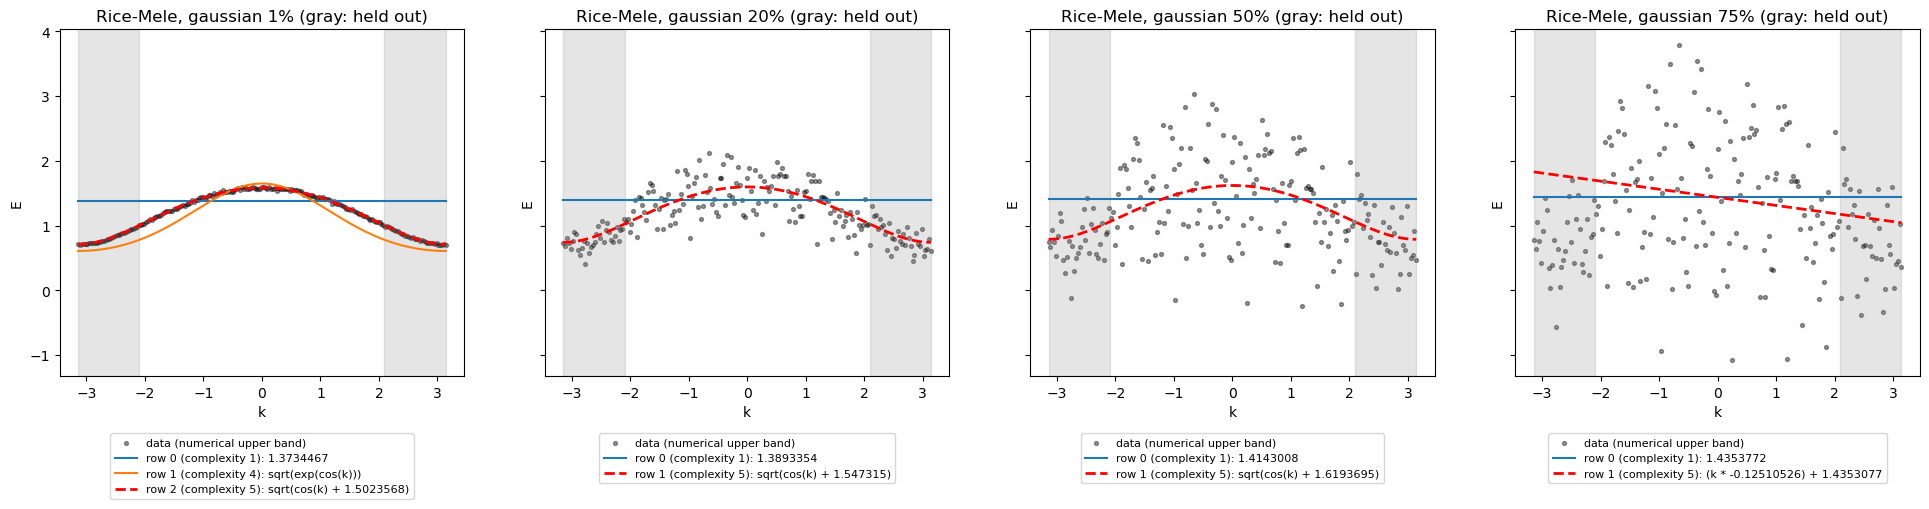

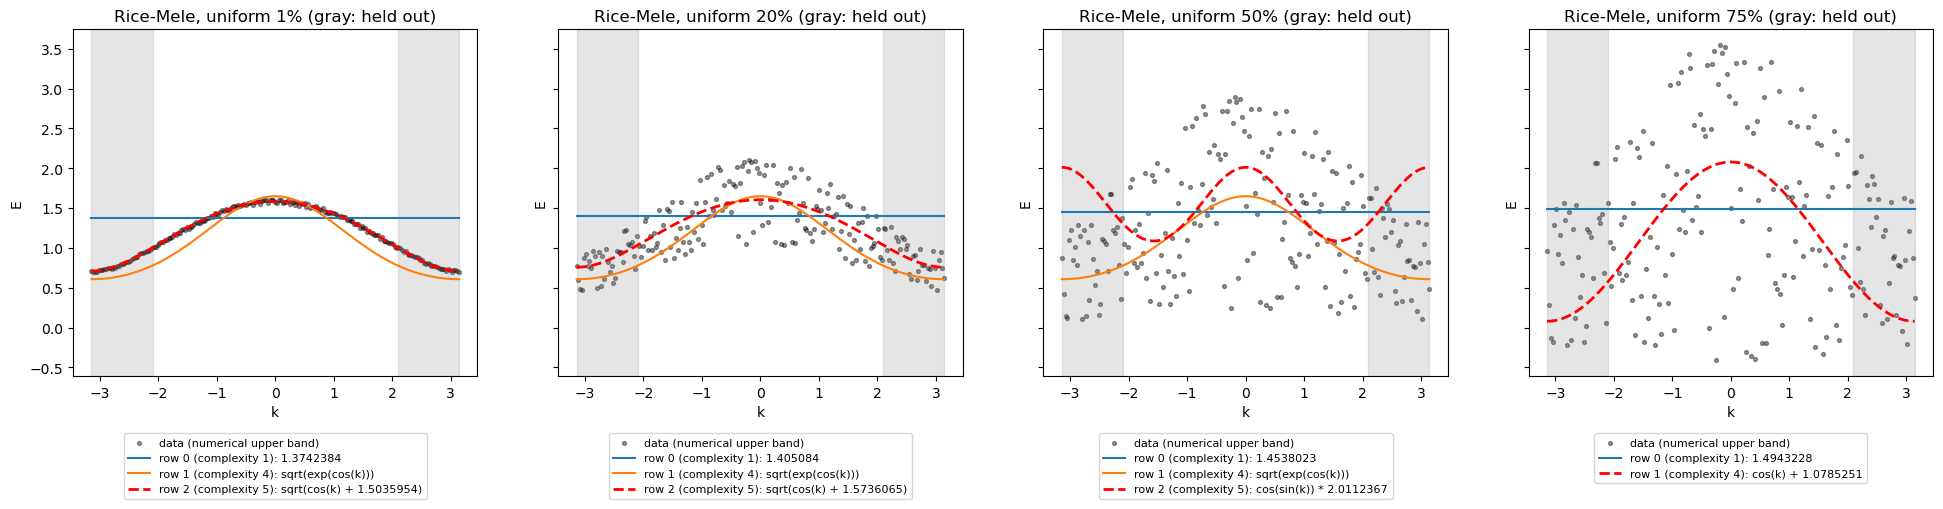

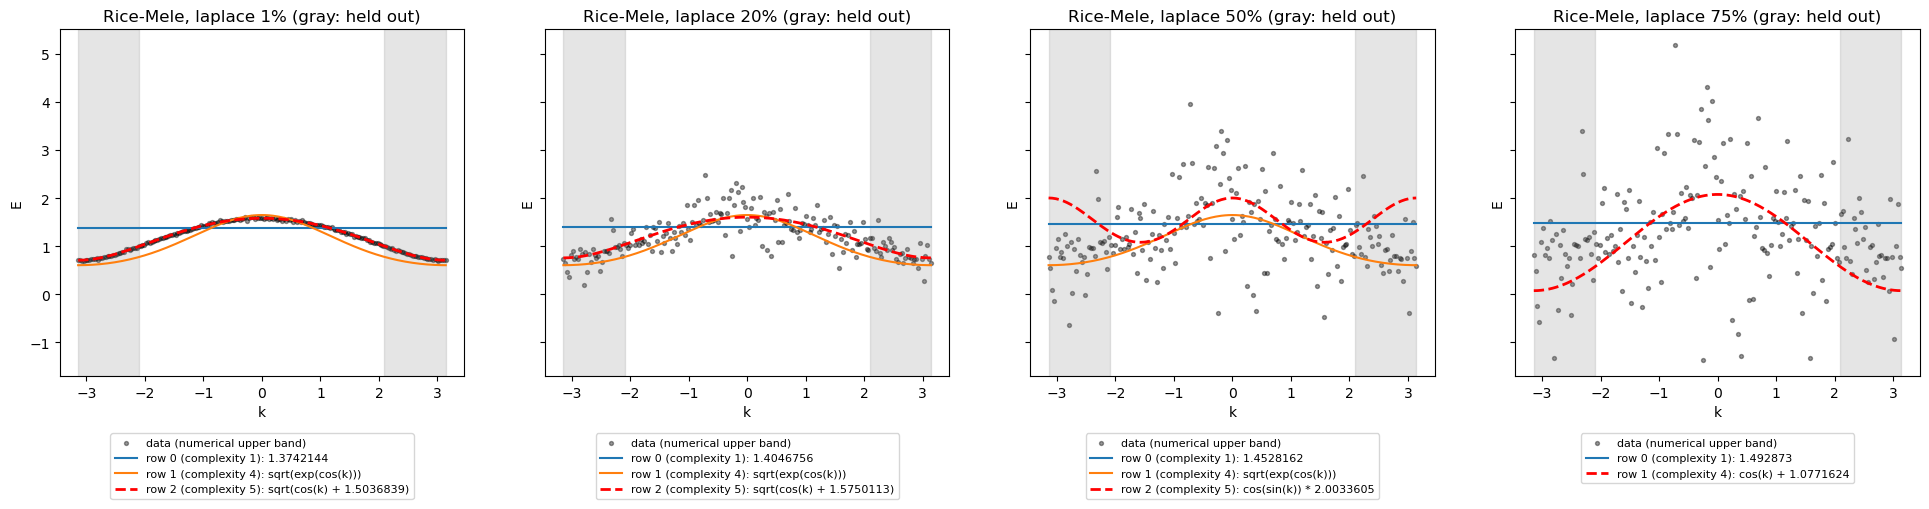

In [12]:
# Knees, picked by hand from the hall of fames above (training loss only, as for SSH)
KNEES_RM = {("gaussian", 0.01): 2, ("gaussian", 0.2): 1, ("gaussian", 0.5): 1, ("gaussian", 0.75): 1,   # 75%: no clear knee
            ("uniform",  0.01): 2, ("uniform",  0.2): 2, ("uniform",  0.5): 2, ("uniform",  0.75): 1,
            ("laplace",  0.01): 2, ("laplace",  0.2): 2, ("laplace",  0.5): 2, ("laplace",  0.75): 1}
table_rm = sweep_table(results_rm, KNEES_RM, rm_upper_band)
display(table_rm.round(3))
plot_sweep(results_rm, KNEES_RM, "Rice-Mele")


**Noise-sweep results, Rice–Mele** (truth $\sqrt{1.5 + \cos k}$, $E_g = 1.414$). Each entry is the hand-picked knee, its gap, and its held-out error.

| Level | Gaussian | Uniform | Laplace |
|---|---|---|---|
| 1% | $\sqrt{\cos k + 1.502}$: 1.418, 0.2% | $\sqrt{\cos k + 1.504}$: 1.419, 0.4% | $\sqrt{\cos k + 1.504}$: 1.419, 0.4% |
| 20% | $\sqrt{\cos k + 1.547}$: 1.480, 4.6% | $\sqrt{\cos k + 1.574}$: 1.515, 7.1% | $\sqrt{\cos k + 1.575}$: 1.517, 7.2% |
| 50% | $\sqrt{\cos k + 1.619}$: 1.574, 11% | $2.01\cos(\sin k)$: 2.17, 184% | $2.00\cos(\sin k)$: 2.17, 183% |
| 75% | $1.435 - 0.125k$: 2.09, 49% (no clear knee) | $\cos k + 1.079$: 0.16, 89% | $\cos k + 1.077$: 0.15, 89% |

- Up to 20% noise, all three distributions keep the exact form. That's better than SSH, where uniform and Laplace noise had already lost it at 20%. So which distribution "fails first" changes with the case, and these single-seed runs can't rank the distributions.
- At 50% noise or more, the knee formulas are no longer bands. $\cos(\sin k)$ has the same value at $k = 0$ and $k = \pi$, so it has no dispersion there. $1.435 - 0.125k$ breaks $E(k) = E(-k)$. The decoy $a + b\cos k$ finally wins at 75%, and its gap of 0.16 is far off. The held-out error flags all of these.


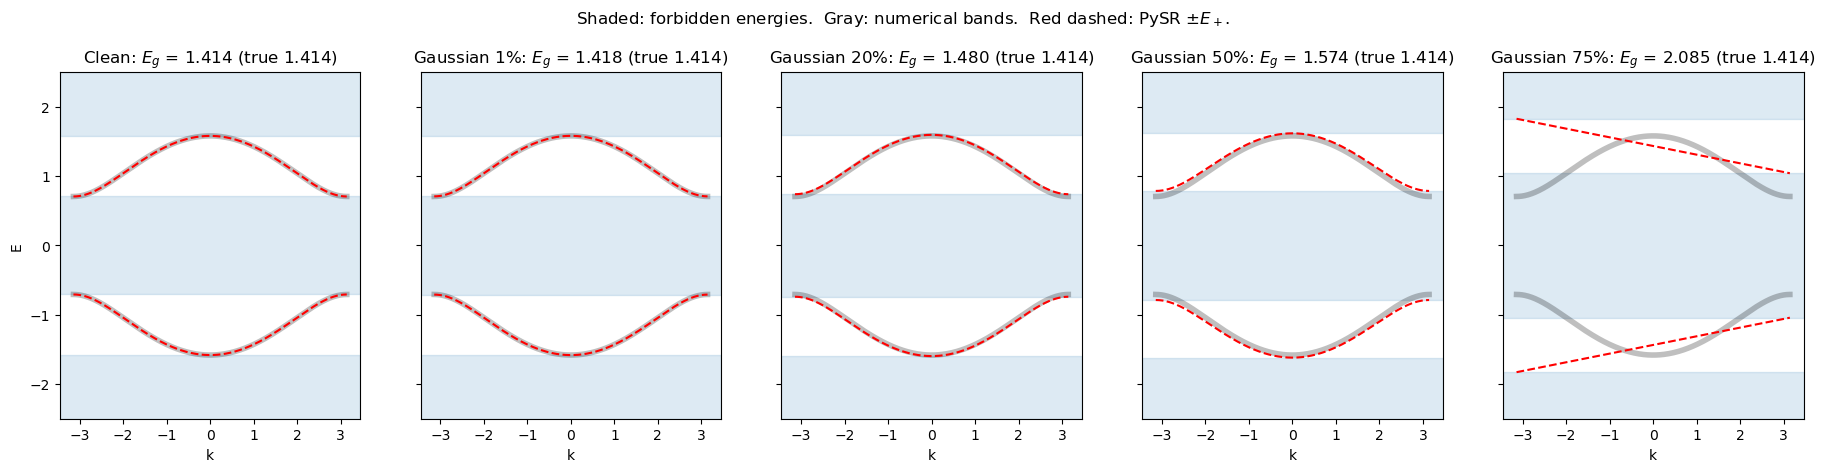

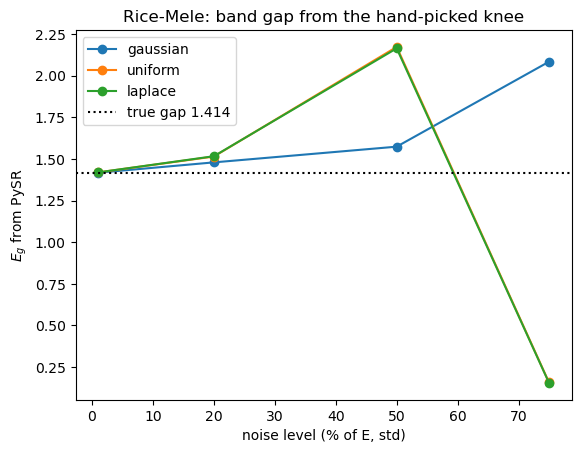

In [13]:
# Rice-Mele band gap from each PySR fit: clean and the four Gaussian levels, then the gap vs. noise for every distribution
plot_gaps([(model_rm, i_rm, "Clean")] + [(results_rm["gaussian", l][2], KNEES_RM["gaussian", l], f"Gaussian {l:.0%}") for l in LEVELS],
          lambda k: rice_mele_model(k, T1_RM, T2_RM, DELTA), GAP_RM)
plot_gap_vs_noise(table_rm, GAP_RM, "Rice-Mele: band gap from the hand-picked knee")
